In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
from scipy.ndimage import gaussian_filter
from plotting import plot3d 

In [ ]:
path = Path("/spin/geofwi3d/large_models_256_v2_3000/")
# path = Path("../allmodels_256/") # change this to the path to the 256 models

n = 256

frames = [100, 150, 180] 
channel_sigma = 20.0      
channel_threshold = 2.0   

rng = np.random.default_rng(2026)

params = pd.read_csv(path / "parameters.csv")
params = params.set_index("sample_index")


mask_cmap = ListedColormap([
    "#2ca02c",
    "#d62728",
    "#ff7f0e",
])

mask_cmap.set_under((0, 0, 0, 0))

def select_model(model_class, subgroup=None):
    rows = params[params["model_class"] == model_class]
    if subgroup is not None:
        rows = rows[rows["subgroup"] == subgroup]
    indices = rows.index.to_numpy(dtype=int)    
    idx = int(rng.choice(indices))

    return idx

def read_volume(idx, filename):
    file = path / f"model_{idx:04d}" / filename
    if not file.is_file():

        raise FileNotFoundError(file)

    return np.fromfile(
        file,
        dtype="<f4"
    ).reshape((n, n, n), order="F")

def make_figure(rows, filename):
    fig = plt.figure(figsize=(15, 3.2 * len(rows)))
    gs = fig.add_gridspec(
        len(rows),
        4,
        wspace=0.02,
        hspace=0.03,
    )

    col_labels = [
        r"Velocity ($V_p$)",
        "Seismic image",
        "RGT",
        "Geological features",
    ]

    selected = []

    for i, (label, model_class, subgroup) in enumerate(rows):
        idx = select_model(model_class, subgroup)
        selected.append({
            "figure": filename,
            "row_label": label,
            "model_class": model_class,
            "subgroup": subgroup,
            "sample_index": idx,
        })

        print(f"{label}: model_{idx:04d}")

        ## Load volumes
        vp = read_volume(idx, "vp3d.bin")
        image = read_volume(idx, "image3d.bin")
        rgt = read_volume(idx, "rgt3d.bin")
        model_dir = path / f"model_{idx:04d}"
        fault_file = model_dir / "fault3d.bin"
        karst_file = model_dir / "karst3d.bin"

        ## IMPORTANT : Unlike 96x96x96 models, 256x256x256 models have fault and karst files if these structures are present.
        fault = (
            read_volume(idx, "fault3d.bin")
            if fault_file.exists()
            else None
        )

        karst = (
            read_volume(idx, "karst3d.bin")
            if karst_file.exists()
            else None
        )

        # Estimate channel-incision volume and find nonzero frames

        row_frames = frames.copy()
        channel_mask = None

        if model_class == "channel":
            # assuming large vertical RGT jump corresponds to channel depth.
            drgt = np.abs(np.diff(rgt, axis=0))
            surface = np.argmax(drgt, axis=0).astype(np.float32)
            del drgt

            # A smoothed reference surface approximates the pre-incision level.
            background = gaussian_filter(surface, sigma=channel_sigma)
            incision = surface - background
            footprint = incision > channel_threshold

            z = np.arange(n, dtype=np.float32)[:, None, None]
            channel_mask = (
                footprint[None, :, :]
                & (z >= background[None, :, :])
                & (z <= surface[None, :, :])
            )

            # Select the slice with maximum channel coverage, then vertical
            # section positions crossing the most channel voxels.
            z_counts = np.count_nonzero(channel_mask, axis=(1, 2))
            if not np.any(z_counts):
                raise ValueError(
                    f"model_{idx:04d}: estimated 3D channel mask is empty. "
                    "Inspect the RGT surface pick or adjust channel_sigma/threshold."
                )

            z_frame = int(np.argmax(z_counts))
            x_counts = np.count_nonzero(channel_mask[z_frame], axis=1)
            y_counts = np.count_nonzero(channel_mask[z_frame], axis=0)
            x_options = np.flatnonzero(x_counts == x_counts.max())
            y_options = np.flatnonzero(y_counts == y_counts.max())
            x_frame = int(x_options[len(x_options) // 2])
            y_frame = int(y_options[len(y_options) // 2])
            row_frames = [z_frame, x_frame, y_frame]
            selected[-1]["depth_frame"] = z_frame
            selected[-1]["x_frame"] = x_frame
            selected[-1]["y_frame"] = y_frame
            print(f"  Channel frames [Z, X, Y]: {row_frames}")

        # Velocity

        ax = fig.add_subplot(gs[i, 0], projection="3d")
        plt.sca(ax)
        plot3d(
            vp,
            cmap="jet",
            vmin=1500,
            vmax=4600,
            frames=row_frames,
            ifinside=False,
            showf=False,
            ifnewfig=False,
            close=False,
            dx=1,
            dy=1,
            dz=1,
        )

        ax.axis("off")
        ax.set_rasterized(True)
        ax.text2D(
            -0.15, 0.5,
            label,
            transform=ax.transAxes,
            fontsize=13,
            fontweight="bold",
            va="center",
            ha="right",
        )

        if i == 0:
            ax.set_title(col_labels[0], fontsize=14, pad=10)

        # Seismic image

        ax = fig.add_subplot(gs[i, 1], projection="3d")
        plt.sca(ax)
        clip = np.percentile(np.abs(image), 99.5)
        clip = max(float(clip), 1e-8)

        plot3d(
            image,
            cmap="Greys",
            vmin=-clip,
            vmax=clip,
            frames=row_frames,
            ifinside=False,
            showf=False,
            ifnewfig=False,
            close=False,
            dx=1,
            dy=1,
            dz=1,
        )

        ax.axis("off")
        ax.set_rasterized(True)
        if i == 0:
            ax.set_title(col_labels[1], fontsize=14, pad=10)

        # Relative geological time

        ax = fig.add_subplot(gs[i, 2], projection="3d")
        plt.sca(ax)

        plot3d(
            rgt,
            cmap="terrain",
            vmin=0,
            vmax=max(float(np.max(rgt)), 1.0),
            frames=row_frames,
            ifinside=False,
            showf=False,
            ifnewfig=False,
            close=False,
            dx=1,
            dy=1,
            dz=1,
        )

        ax.axis("off")
        ax.set_rasterized(True)
        if i == 0:
            ax.set_title(col_labels[2], fontsize=14, pad=10)

        # Geological features

        if model_class == "channel":
            ax = fig.add_subplot(gs[i, 3], projection="3d")
            plt.sca(ax)

            channel_cmap = plt.get_cmap("Purples").copy()
            channel_cmap.set_under((0, 0, 0, 0))

            plot3d(
                channel_mask.astype(np.float32),
                cmap=channel_cmap,
                vmin=0.5,
                vmax=1.5,
                frames=row_frames,
                ifinside=False,
                showf=False,
                ifnewfig=False,
                close=False,
                alpha=0.95,
                dx=1, dy=1, dz=1,
                antialiased=False,
            )

            ax.axis("off")
            ax.set_rasterized(True)

        else:
            ax = fig.add_subplot(gs[i, 3], projection="3d")
            plt.sca(ax)

            if model_class == "layered_folding":
                ax.text2D(
                    0.5, 0.5,
                    "—",
                    transform=ax.transAxes,
                    fontsize=22,
                    color="gray",
                    ha="center",
                    va="center",
                )

            else:

                combined_mask = np.zeros(
                    (n, n, n),
                    dtype=np.float32,
                )

                # Salt = 1

                if model_class in ("salt", "salt_fault"):
                    combined_mask[rgt == 0] = 1

                # Fault = 2

                if fault is not None:
                    combined_mask[fault != 0] = 2

                # Karst = 3

                if karst is not None:
                    combined_mask[karst != 0] = 3

                plot3d(
                    combined_mask,
                    cmap=mask_cmap,
                    vmin=0.5,
                    vmax=3.5,
                    frames=row_frames,
                    ifinside=False,
                    showf=False,
                    ifnewfig=False,
                    close=False,
                    alpha=0.95,
                    dx=1,
                    dy=1,
                    dz=1,
                    antialiased=False,
                )

            ax.axis("off")
            ax.set_rasterized(True)

        if i == 0:
            ax.set_title(col_labels[3], fontsize=14, pad=10)

    fig.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.05,
    )

    plt.show()
    plt.close(fig)
    return selected

Layered / folded: model_2525


Fault: model_0497
Salt: model_0062
Salt + fault: model_1948
Channel: model_1174
  Channel frames [Z, X, Y]: [73, 10, 18]
Karst: model_1442


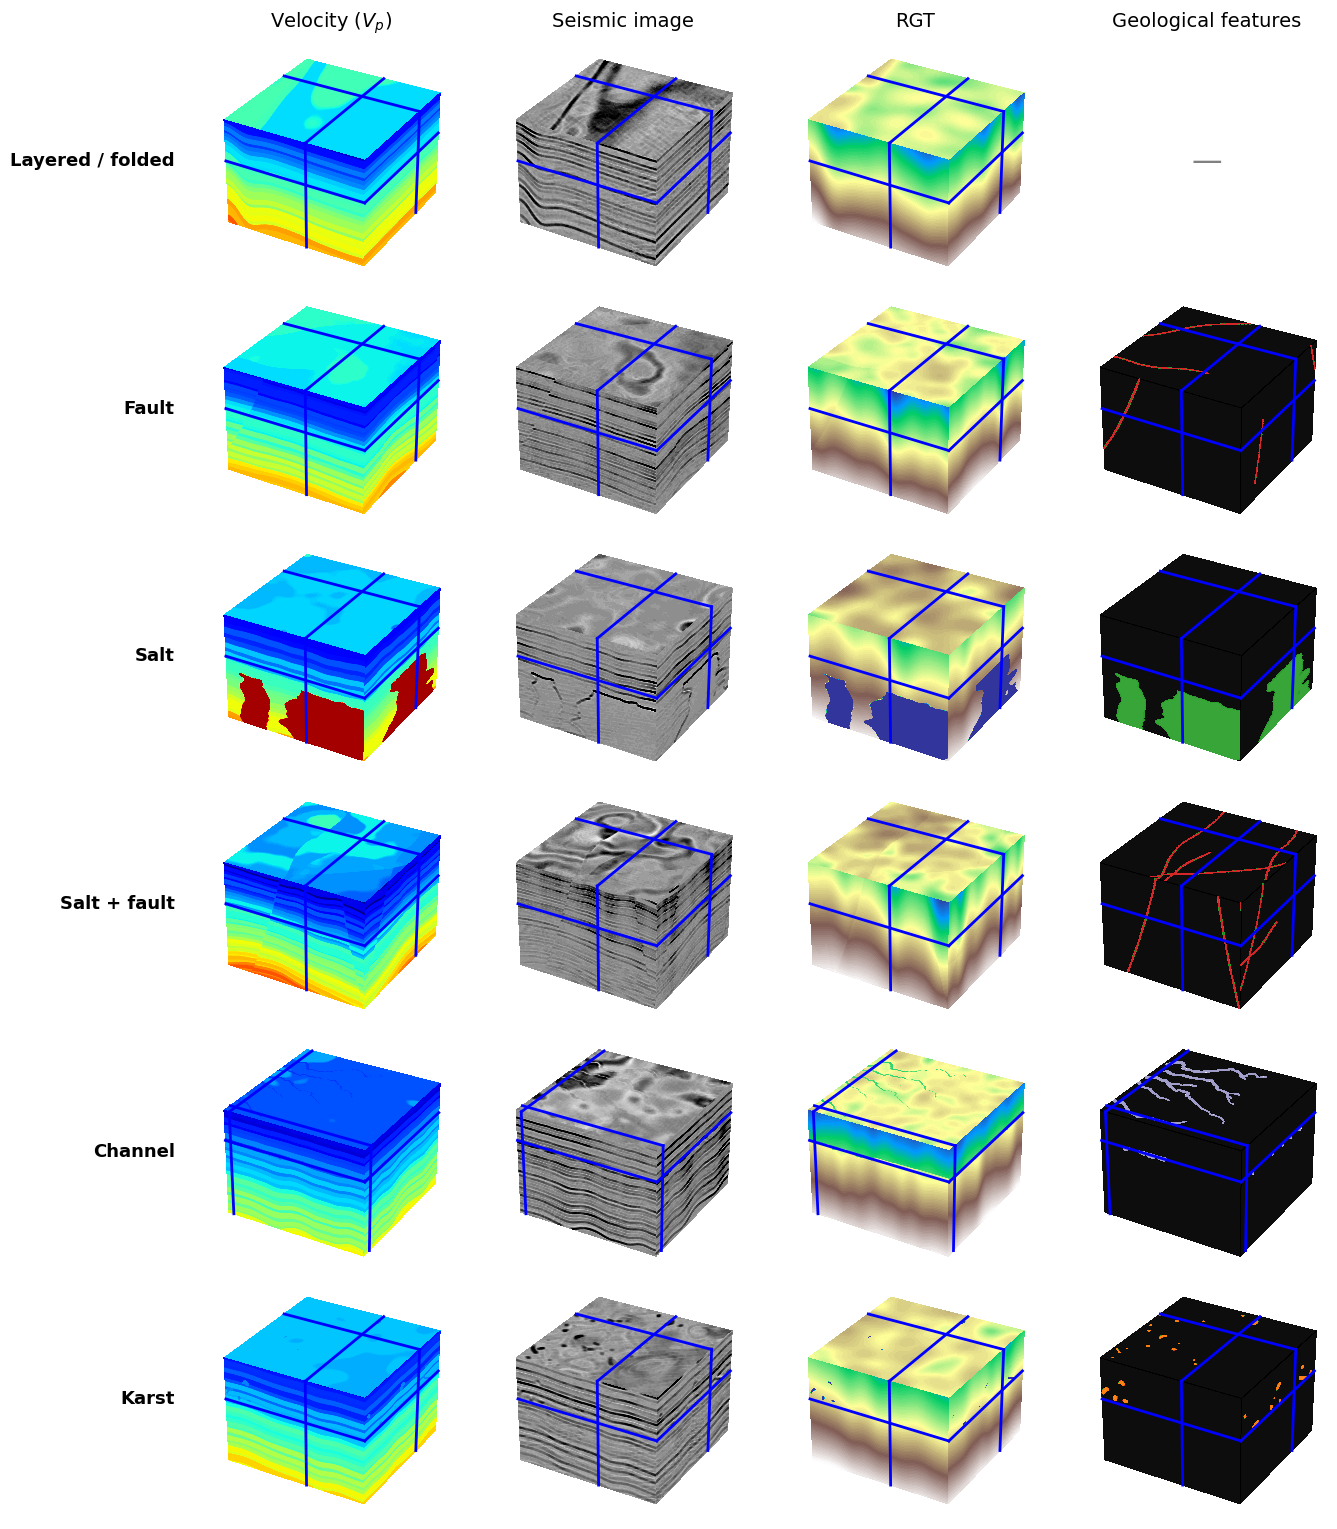

Meander channel: model_0358
  Channel frames [Z, X, Y]: [78, 201, 188]
Meander canyon: model_1177
  Channel frames [Z, X, Y]: [118, 21, 197]
Drainage channel: model_2096
  Channel frames [Z, X, Y]: [72, 195, 254]
Drainage canyon: model_1037
  Channel frames [Z, X, Y]: [55, 123, 138]
Karst: model_2540
Karst + fault: model_2381


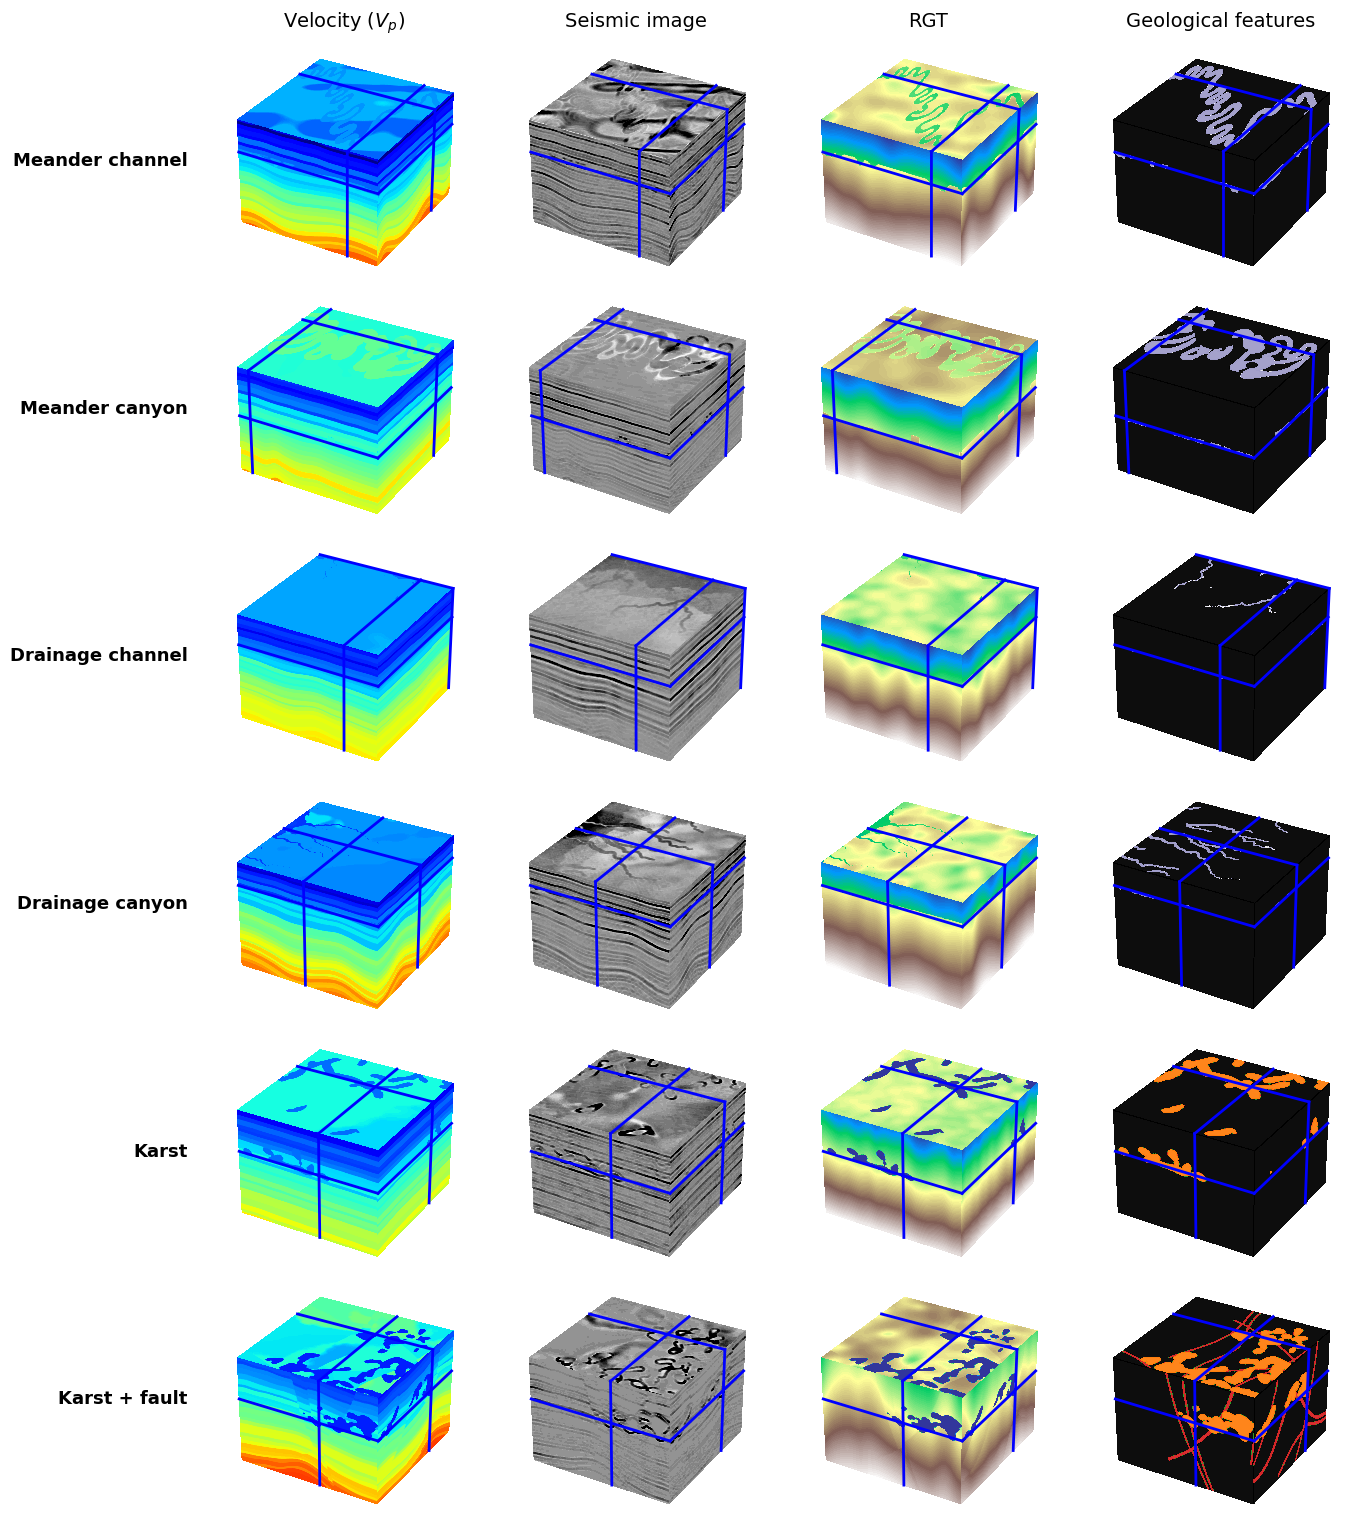

                                 figure         row_label      model_class  \
0     ../gallery/models-256-classes.png  Layered / folded  layered_folding   
1     ../gallery/models-256-classes.png             Fault            fault   
2     ../gallery/models-256-classes.png              Salt             salt   
3     ../gallery/models-256-classes.png      Salt + fault       salt_fault   
4     ../gallery/models-256-classes.png           Channel          channel   
5     ../gallery/models-256-classes.png             Karst            karst   
6   ../gallery/models-256-subgroups.png   Meander channel          channel   
7   ../gallery/models-256-subgroups.png    Meander canyon          channel   
8   ../gallery/models-256-subgroups.png  Drainage channel          channel   
9   ../gallery/models-256-subgroups.png   Drainage canyon          channel   
10  ../gallery/models-256-subgroups.png             Karst            karst   
11  ../gallery/models-256-subgroups.png     Karst + fault       

In [3]:
main_rows = [
    ("Layered / folded", "layered_folding", None),
    ("Fault", "fault", None),
    ("Salt", "salt", None),
    ("Salt + fault", "salt_fault", None),
    ("Channel", "channel", None),
    ("Karst", "karst", None),
]

selected_main = make_figure(
    main_rows,
    "../gallery/models-256-classes.png",
)

subtype_rows = [
    ("Meander channel", "channel", "meander_channel"),
    ("Meander canyon", "channel", "meander_canyon"),
    ("Drainage channel", "channel", "drainage_channel"),
    ("Drainage canyon", "channel", "drainage_canyon"),
    ("Karst", "karst", "karst_unfaulted"),
    ("Karst + fault", "karst", "karst_faulted"),
]

selected_subtypes = make_figure(
    subtype_rows,
    "../gallery/models-256-subgroups.png",
)

selected_df = pd.DataFrame(

    selected_main + selected_subtypes

)


print(selected_df)


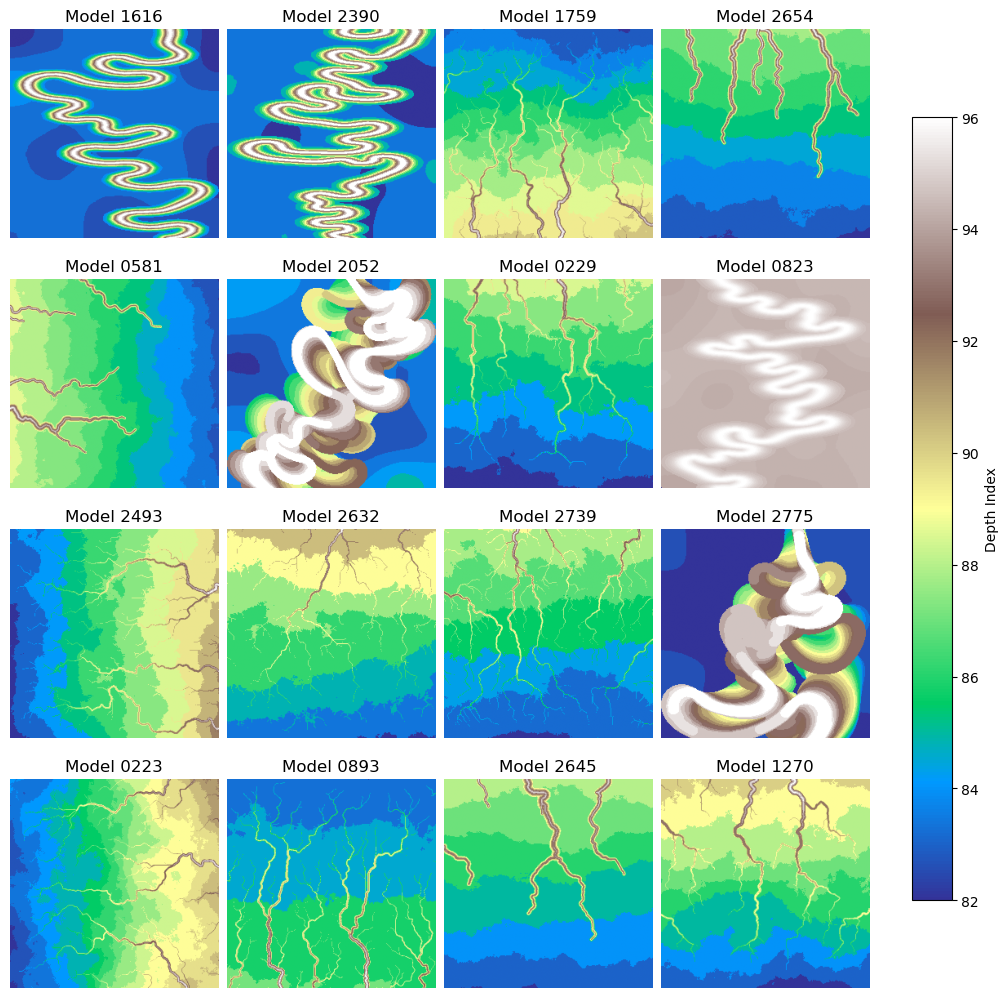

In [4]:
chanel_idx = params.loc[(params["model_class"] == "channel")].index.to_numpy(dtype=int)
n1 = 256

np.random.seed(2026)
chanel_idx = chanel_idx[np.random.randint(0, 499, 16)]

fig, axes = plt.subplots(4, 4, figsize=(10, 10), constrained_layout=True)
axes = axes.flatten()

for idx, ax in zip(chanel_idx, axes):
    file = f"/spin/geofwi3d/large_models_256_v2_3000//model_{idx:04d}/rgt3d.bin"
    rgt = np.memmap(file, dtype=np.float32, mode="r", shape=(n1, n1, n1), order="F")

    drgt = np.abs(np.diff(rgt, axis=0))

    surface = np.argmax(drgt, axis=0)

    im = ax.imshow(surface, cmap="terrain")
    ax.axis("off")
    ax.set_title(f"Model {idx:04d}")

cbar = fig.colorbar(im, ax=axes, shrink=0.8, location="right")
cbar.set_label("Depth Index")

plt.show()
